**Q1**



In [1]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

text = """Artificial intelligence is transforming the world through smart technologies.
Machine learning helps computers learn patterns from data and make predictions.
AI tools can improve education, healthcare, and communication.
However, responsible development is essential to protect privacy and reduce bias.
I enjoy learning about AI because it combines creativity, mathematics, and problem solving.
In the future, intelligent systems may help people solve many complex problems."""

print("Original text:\n", text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("\nCleaned text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord tokens:\n", words)
print("\nSentences:")
for i, sentence in enumerate(sentences, 1):
    print(i, sentence)

print("\nsplit():\n", clean_text.split())
print("\nword_tokenize():\n", word_tokenize(text))

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("\nTokens after stopword removal:\n", filtered_words)

frequency = FreqDist(filtered_words)
print("\nWord frequency distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")


Original text:
 Artificial intelligence is transforming the world through smart technologies.
Machine learning helps computers learn patterns from data and make predictions.
AI tools can improve education, healthcare, and communication.
However, responsible development is essential to protect privacy and reduce bias.
I enjoy learning about AI because it combines creativity, mathematics, and problem solving.
In the future, intelligent systems may help people solve many complex problems.

Cleaned text:
 artificial intelligence is transforming the world through smart technologies
machine learning helps computers learn patterns from data and make predictions
ai tools can improve education healthcare and communication
however responsible development is essential to protect privacy and reduce bias
i enjoy learning about ai because it combines creativity mathematics and problem solving
in the future intelligent systems may help people solve many complex problems

Word tokens:
 ['artificial', 

**Q2**

In [2]:

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [porter.stem(word) for word in filtered_words]

tagged_words = pos_tag(filtered_words)

def get_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('R'):
        return 'r'
    return 'n'

lemmatized_words = [
    lemmatizer.lemmatize(word, get_pos(tag))
    for word, tag in tagged_words
]

print("Alphabetic words:\n", words)
print("\nWords after stopword removal:\n", filtered_words)
print("\nPorter stemmed words:\n", stemmed_words)
print("\nPOS-aware lemmatized words:\n", lemmatized_words)

print("\nComparison:")
for word, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(f"{word:15} -> Stem: {stem:12} Lemma: {lemma}")


Alphabetic words:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'through', 'smart', 'technologies', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'from', 'data', 'and', 'make', 'predictions', 'ai', 'tools', 'can', 'improve', 'education', 'healthcare', 'and', 'communication', 'however', 'responsible', 'development', 'is', 'essential', 'to', 'protect', 'privacy', 'and', 'reduce', 'bias', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'combines', 'creativity', 'mathematics', 'and', 'problem', 'solving', 'in', 'the', 'future', 'intelligent', 'systems', 'may', 'help', 'people', 'solve', 'many', 'complex', 'problems']

Words after stopword removal:
 ['artificial', 'intelligence', 'transforming', 'world', 'smart', 'technologies', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns', 'data', 'make', 'predictions', 'ai', 'tools', 'improve', 'education', 'healthcare', 'communication', 'however', 'responsible', 'development', 'ess

Stemming is faster and useful when processing large amounts of text for information retrieval or search. Lemmatization is preferable when meaningful dictionary words are needed because it considers linguistic forms and, with POS tagging, the grammatical role of words.

**Q3**

In [3]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "Artificial intelligence helps computers learn and make smart decisions.",
    "Machine learning uses data to train models and predict future outcomes.",
    "Cybersecurity protects computers, networks, and personal data from attacks."
]

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("BAG OF WORDS")
display(bow_df)

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("TF-IDF SCORES")
display(tfidf_df.round(3))

print("\nTOP 3 KEYWORDS FOR EACH TEXT")
feature_names = tfidf_vectorizer.get_feature_names_out()

for i, text_name in enumerate(["Text 1", "Text 2", "Text 3"]):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\n{text_name}:")
    for idx in top_indices:
        print(f"{feature_names[idx]}: {scores[idx]:.3f}")


BAG OF WORDS


,and,artificial,attacks,computers,cybersecurity,data,decisions,from,future,helps,...,models,networks,outcomes,personal,predict,protects,smart,to,train,uses
Text 1,1,1,0,1,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
Text 2,1,0,0,0,0,1,0,0,1,0,...,1,0,1,0,1,0,0,1,1,1
Text 3,1,0,1,1,1,1,0,1,0,0,...,0,1,0,1,0,1,0,0,0,0


TF-IDF SCORES


,and,artificial,attacks,computers,cybersecurity,data,decisions,from,future,helps,...,models,networks,outcomes,personal,predict,protects,smart,to,train,uses
Text 1,0.210,0.355,0.000,0.270,0.000,0.000,0.355,0.000,0.000,0.355,...,0.000,0.000,0.000,0.000,0.000,0.000,0.355,0.000,0.000,0.000
Text 2,0.187,0.000,0.000,0.000,0.000,0.241,0.000,0.000,0.317,0.000,...,0.317,0.000,0.317,0.000,0.317,0.000,0.000,0.317,0.317,0.317
Text 3,0.216,0.000,0.365,0.278,0.365,0.278,0.000,0.365,0.000,0.000,...,0.000,0.365,0.000,0.365,0.000,0.365,0.000,0.000,0.000,0.000



TOP 3 KEYWORDS FOR EACH TEXT

Text 1:
smart: 0.355
learn: 0.355
intelligence: 0.355

Text 2:
uses: 0.317
train: 0.317
to: 0.317

Text 3:
protects: 0.365
networks: 0.365
personal: 0.365


**Q4**

In [4]:

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence enables computers to learn from data.
AI systems recognize patterns and make predictions.
Machine learning improves performance through training.
Artificial intelligence is used in healthcare and education.
AI automates tasks and supports decision making."""

text2 = """Blockchain stores information in linked digital blocks.
Transactions are recorded across a distributed network.
Cryptography helps secure blockchain records.
Blockchain supports transparency and decentralized applications.
It is used in finance and digital contracts."""

def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    return text.split()

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Text 1 tokens:", tokens1)
print("\nText 2 tokens:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])
cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("\nJaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine, 4))


Text 1 tokens: ['artificial', 'intelligence', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'systems', 'recognize', 'patterns', 'and', 'make', 'predictions', 'machine', 'learning', 'improves', 'performance', 'through', 'training', 'artificial', 'intelligence', 'is', 'used', 'in', 'healthcare', 'and', 'education', 'ai', 'automates', 'tasks', 'and', 'supports', 'decision', 'making']

Text 2 tokens: ['blockchain', 'stores', 'information', 'in', 'linked', 'digital', 'blocks', 'transactions', 'are', 'recorded', 'across', 'a', 'distributed', 'network', 'cryptography', 'helps', 'secure', 'blockchain', 'records', 'blockchain', 'supports', 'transparency', 'and', 'decentralized', 'applications', 'it', 'is', 'used', 'in', 'finance', 'and', 'digital', 'contracts']

Jaccard Similarity: 0.0926
Cosine Similarity: 0.1391


Jaccard similarity measures the overlap between the unique words in the two texts, ignoring word frequency. Cosine similarity compares their TF-IDF vectors and considers the importance of words. In this case, cosine similarity may provide more useful insights because it accounts for the relative importance of terms, while Jaccard similarity considers only whether a word is present or absent. Both metrics help compare the topics discussed in the two technologies.

**Q5**

,Review,Polarity,Subjectivity,Sentiment
0,This product is amazing and works perfectly.,0.800,0.950,Positive
1,Excellent quality and fast delivery.,0.600,0.800,Positive
2,I love this product and highly recommend it.,0.330,0.570,Positive
3,The service was terrible and disappointing.,-0.800,0.850,Negative
4,Very poor quality and a waste of money.,-0.360,0.390,Negative
5,I am unhappy with this purchase.,-0.600,0.900,Negative
6,The product is okay and works as expected.,0.200,0.450,Positive
7,"The service was average, nothing special.",0.104,0.486,Positive


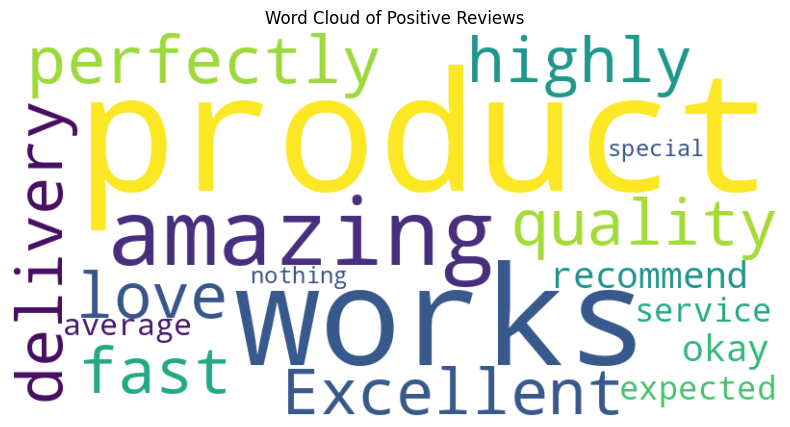

In [5]:

!pip install -q textblob wordcloud

from textblob import TextBlob
from wordcloud import WordCloud
import pandas as pd
import matplotlib.pyplot as plt

reviews = [
    "This product is amazing and works perfectly.",
    "Excellent quality and fast delivery.",
    "I love this product and highly recommend it.",
    "The service was terrible and disappointing.",
    "Very poor quality and a waste of money.",
    "I am unhappy with this purchase.",
    "The product is okay and works as expected.",
    "The service was average, nothing special."
]

results = []

for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append({
        "Review": review,
        "Polarity": round(polarity, 3),
        "Subjectivity": round(subjectivity, 3),
        "Sentiment": sentiment
    })

df = pd.DataFrame(results)
display(df)

positive_reviews = " ".join(
    df[df["Sentiment"] == "Positive"]["Review"]
)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_reviews)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


**Q6**

In [6]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is changing the world through technology.
Machine learning helps computers learn from data and identify patterns.
Deep learning uses neural networks to solve complex problems.
Natural language processing allows computers to understand human language.
Computer vision helps machines recognize images and objects.
Data science uses statistics and programming to discover useful information.
Cloud computing provides flexible storage and computing resources.
Cybersecurity protects systems and data from digital threats.
Robotics combines engineering, programming, and intelligent machines.
Technology continues to improve healthcare, education, and communication.
Learning new technologies helps students develop problem solving skills.
Artificial intelligence can automate tasks and support decision making.
Machine learning models improve when trained with quality data.
Computers are becoming more useful in everyday life.
Responsible technology development is important for society."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []

for line in text.split("."):
    sequence = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(sequence) + 1):
        input_sequences.append(sequence[:i])

max_sequence_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")

X = input_sequences[:, :-1]
y = tf.keras.utils.to_categorical(input_sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 50, input_length=max_sequence_len - 1),
    LSTM(100),
    Dense(total_words, activation="softmax")
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(X, y, epochs=100, verbose=0)

def generate_text(seed_text, next_words=25):
    for _ in range(next_words):
        sequence = tokenizer.texts_to_sequences([seed_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_sequence_len - 1, padding="pre")
        predicted = model.predict(sequence, verbose=0)
        predicted_word = tokenizer.index_word.get(int(np.argmax(predicted)), "")
        if not predicted_word:
            break
        seed_text += " " + predicted_word
    return seed_text

print("Generated Text:\n")
print(generate_text("artificial", 25))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Generated Text:

artificial intelligence is changing the world through technology technology technology technology society technology technology skills skills information information information skills skills skills skills skills skills skills
